# 🔬 ABLATION STUDY v2 — Kontribusi Fitur Sentimen (hybrid GARCH)
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### Rancangan (identik dengan MODEL_xgboost v4 & MODEL_lstm v5)
| Skenario | Fitur |
|---|---|
| **X1** (tanpa sentimen) | 15 teknikal, termasuk `R_Exit` & `GARCH_Forecast` |
| **X1 + X2** (dengan sentimen) | 15 teknikal + 4 sentimen = 19 |

Setiap skenario **di-tuning ulang** dengan anggaran identik. Target, transformasi (`TARGET_MODE='ratio'`), arsitektur, *window* sekuens (memuat hari t), dan tanggal uji **sama persis** dengan notebook model utama — sehingga skenario X1+X2 mereproduksi hasil utama.

### Keluaran (menjawab Reviewer 1 #1/#3 & Reviewer 2 #3)
1. **Tabel ablation** dengan konvensi tanda jelas: **Perubahan RMSE (%) = (RMSE_X1+X2 − RMSE_X1) / RMSE_X1 × 100 → negatif = sentimen membantu**, plus **uji Diebold–Mariano** per emiten.
2. **Analisis kondisi pasar**: kapan sentimen membantu — hari berberita vs tanpa berita, rezim volatilitas tinggi vs rendah, sentimen negatif vs non-negatif.
3. `hasil_prediksi_ablation.csv` — prediksi harian kedua skenario (untuk audit & uji lanjutan).

## ⚙️ CELL 1 — Konfigurasi

In [1]:
import os, random, warnings, itertools, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 10, 'figure.dpi': 150})

ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR): d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y = 'Volatilitas_Target'
TARGET_MODE = 'ratio'          # HARUS sama dengan MODEL_xgboost v4 & MODEL_lstm v5

KOLOM_X1 = ['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
            'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D',
            'Volume_ZScore', 'R_Exit', 'GARCH_Forecast']
KOLOM_X2 = ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']
SKENARIO = {'X1': KOLOM_X1, 'X1+X2': KOLOM_X1 + KOLOM_X2}

# XGBoost — identik MODEL_xgboost v4
PARAM_DIST_XGB = {'n_estimators': [100, 200, 300, 400], 'max_depth': [4, 5, 6, 7],
                  'learning_rate': [0.03, 0.05, 0.1, 0.15], 'subsample': [0.7, 0.8, 1.0],
                  'colsample_bytree': [0.7, 0.8, 1.0], 'min_child_weight': [1, 2, 3],
                  'gamma': [0, 0.1, 0.2]}
N_ITER_TUNING, TSCV = 25, TimeSeriesSplit(n_splits=5)

# LSTM — identik MODEL_lstm v5
GRID_LSTM = {'unit1': [16, 32], 'lr': [1e-3], 'dropout': [0.1, 0.2], 'lookback': [10, 15]}
KOMBINASI_LSTM = [dict(zip(GRID_LSTM, v)) for v in itertools.product(*GRID_LSTM.values())]
EPOCHS_TUNE, PATIENCE_TUNE, VAL_FRAC, BATCH_TUNE = 40, 7, 0.15, 64
EPOCHS, BATCH, PATIENCE = 100, 16, 20
EPS_LOG = 1e-6

print('=' * 72)
for k, v in SKENARIO.items(): print(f'  Skenario {k:6}: {len(v)} fitur')
print(f'  TARGET_MODE     : {TARGET_MODE}')
print('=' * 72)

  Skenario X1    : 15 fitur
  Skenario X1+X2 : 19 fitur
  TARGET_MODE     : ratio


## 🔧 CELL 2 — Fungsi Bantu (identik notebook model) + Uji Diebold–Mariano

In [2]:
def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai, dtype=float) * (cmax - cmin) + cmin

def _mape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); m = np.abs(y) > 1e-8
    return float(np.mean(np.abs((y[m] - p[m]) / y[m])) * 100)

def evaluasi(y, p):
    return {'RMSE': float(np.sqrt(mean_squared_error(y, p))), 'MAE': float(mean_absolute_error(y, p)),
            'MAPE (%)': round(_mape(y, p), 2), 'R2': round(float(r2_score(y, p)), 4)}

def diebold_mariano(y, f1, f2, h=1):
    # DM (MSE loss) + koreksi Harvey-Leybourne-Newbold. DM<0 -> f1 lebih akurat.
    y, f1, f2 = map(lambda a: np.asarray(a, float), (y, f1, f2))
    d = (y - f1) ** 2 - (y - f2) ** 2
    n, dbar = len(d), d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0: return 0.0, 1.0
    stat = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(stat), float(2 * stats.t.sf(abs(stat), df=n - 1))

# ── target XGBoost (identik v4): ratio = 100 x ln(sigma/GARCH)
def target_xgb(df, sc):
    if TARGET_MODE == 'level': return df[KOLOM_Y].values * 100
    y = inverse_transform(df[KOLOM_Y].values, sc); g = inverse_transform(df['GARCH_Forecast'].values, sc, 'GARCH_Forecast')
    return 100 * np.log(np.clip(y, 1e-8, None) / np.clip(g, 1e-8, None))

def xgb_ke_vol(pred, df, sc):
    if TARGET_MODE == 'level': return np.clip(inverse_transform(pred / 100, sc), 0, None)
    g = inverse_transform(df['GARCH_Forecast'].values, sc, 'GARCH_Forecast')
    return np.clip(g, 1e-8, None) * np.exp(pred / 100)

# ── target LSTM (identik v5): ratio = ln(sigma/GARCH)
def target_z(df, sc):
    y = np.clip(inverse_transform(df[KOLOM_Y].values, sc), EPS_LOG, None)
    if TARGET_MODE == 'level' or TARGET_MODE == 'log': return np.log(y)
    g = np.clip(inverse_transform(df['GARCH_Forecast'].values, sc, 'GARCH_Forecast'), EPS_LOG, None)
    return np.log(y / g)

def basis_garch(df, sc):
    if TARGET_MODE in ('level', 'log'): return None
    return np.clip(inverse_transform(df['GARCH_Forecast'].values, sc, 'GARCH_Forecast'), EPS_LOG, None)

def z_ke_vol(z, g=None):
    z = np.asarray(z, float).reshape(-1)
    return np.exp(z) if g is None else np.asarray(g, float).reshape(-1) * np.exp(z)

def buat_sekuens(X, y, lb):
    X = np.asarray(X, np.float32); y = np.asarray(y, np.float32).reshape(-1)
    Xs = [X[i - lb + 1:i + 1] for i in range(lb - 1, len(X))]
    return np.array(Xs, np.float32), y[lb - 1:].astype(np.float32)

def sekuens_uji(X_tr, X_te, lb):
    X_full = np.vstack([np.asarray(X_tr, np.float32)[-(lb - 1):], np.asarray(X_te, np.float32)])
    return np.array([X_full[i - lb + 1:i + 1] for i in range(lb - 1, len(X_full))], np.float32)

def buat_model_lstm(n_fitur, lb, unit1=32, dropout=0.2, lr=1e-3):
    m = Sequential([Input(shape=(lb, n_fitur)), LSTM(unit1), Dropout(dropout), Dense(1, activation='linear')])
    m.compile(optimizer=Adam(learning_rate=lr), loss='huber', metrics=['mae'])
    return m

print('✅ Fungsi bantu siap.')

✅ Fungsi bantu siap.


## 📂 CELL 3 — Muat Dataset per Emiten

In [3]:
dict_train, dict_test, dict_scaler = {}, {}, {}
for e in URUTAN_EMITEN:
    tr = pd.read_csv(DIR_FINAL / f'dataset_train_{e}.csv', encoding='utf-8-sig', parse_dates=['Date'])
    te = pd.read_csv(DIR_FINAL / f'dataset_test_{e}.csv', encoding='utf-8-sig', parse_dates=['Date'])
    hilang = [c for c in KOLOM_X1 + KOLOM_X2 + [KOLOM_Y] if c not in tr.columns]
    assert not hilang, f'{e}: kolom hilang {hilang} → jalankan PREP_03 v3'
    dict_train[e] = tr.sort_values('Date').reset_index(drop=True)
    dict_test[e]  = te.sort_values('Date').reset_index(drop=True)
    dict_scaler[e] = pd.read_csv(DIR_FINAL / f'scaler_params_{e}.csv', index_col=0, encoding='utf-8-sig')
    print(f'  OK {e:5}| train={len(tr):4} | test={len(te):4}')

  OK ADRO | train= 859 | test= 215
  OK ADMR | train= 840 | test= 210
  OK ITMG | train= 859 | test= 215
  OK PTBA | train= 859 | test= 215
  OK MEDC | train= 859 | test= 215
  OK AKRA | train= 859 | test= 215
  OK PGAS | train= 859 | test= 215


## 🌳 CELL 4 — Ablation XGBoost (tuning ulang tiap skenario)

In [4]:
hasil, prediksi = [], []
print('=' * 72); print('  🌳 ABLATION XGBoost'); print('=' * 72)
for sk, kol in SKENARIO.items():
    print(f'\n── Skenario {sk} ({len(kol)} fitur)')
    for e in URUTAN_EMITEN:
        tr, te, sc = dict_train[e], dict_test[e], dict_scaler[e]
        X_tr, X_te = tr[kol].values, te[kol].values
        y_tr = target_xgb(tr, sc)
        search = RandomizedSearchCV(XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=-1),
                                    param_distributions=PARAM_DIST_XGB, n_iter=N_ITER_TUNING,
                                    scoring='neg_root_mean_squared_error', cv=TSCV,
                                    random_state=SEED, n_jobs=-1, verbose=0)
        search.fit(X_tr, y_tr)
        params = dict(search.best_params_); params.update(objective='reg:squarederror', random_state=SEED, n_jobs=-1)
        if params.get('max_depth', 6) < 4: params['max_depth'] = 6
        model = XGBRegressor(**params).fit(X_tr, y_tr)
        y_true = inverse_transform(te[KOLOM_Y].values, sc)
        y_pred = xgb_ke_vol(model.predict(X_te), te, sc)
        m = evaluasi(y_true, y_pred)
        hasil.append({'Model': 'XGBoost', 'Skenario': sk, 'Emiten': e, 'N_Fitur': len(kol), **m})
        prediksi.append(pd.DataFrame({'Model': 'XGBoost', 'Skenario': sk, 'Emiten': e, 'Date': te['Date'].values,
                                      'Y_Aktual': y_true, 'Y_Prediksi': y_pred}))
        print(f'   {e:5}: RMSE={m["RMSE"]:.5f} | MAPE={m["MAPE (%)"]:5.2f}% | R2={m["R2"]:.4f}')
print('\n✅ Ablation XGBoost selesai.')

  🌳 ABLATION XGBoost

── Skenario X1 (15 fitur)
   ADRO : RMSE=0.00143 | MAPE= 3.42% | R2=0.9483
   ADMR : RMSE=0.00271 | MAPE= 3.10% | R2=0.9646
   ITMG : RMSE=0.00097 | MAPE= 3.35% | R2=0.9894
   PTBA : RMSE=0.00114 | MAPE= 3.68% | R2=0.9813
   MEDC : RMSE=0.00177 | MAPE= 3.11% | R2=0.9665
   AKRA : RMSE=0.00112 | MAPE= 3.01% | R2=0.9619
   PGAS : RMSE=0.00156 | MAPE= 3.07% | R2=0.9662

── Skenario X1+X2 (19 fitur)
   ADRO : RMSE=0.00149 | MAPE= 3.76% | R2=0.9441
   ADMR : RMSE=0.00272 | MAPE= 3.11% | R2=0.9643
   ITMG : RMSE=0.00096 | MAPE= 3.36% | R2=0.9896
   PTBA : RMSE=0.00118 | MAPE= 3.71% | R2=0.9800
   MEDC : RMSE=0.00177 | MAPE= 3.07% | R2=0.9664
   AKRA : RMSE=0.00111 | MAPE= 2.97% | R2=0.9623
   PGAS : RMSE=0.00155 | MAPE= 2.94% | R2=0.9668

✅ Ablation XGBoost selesai.


## 🧠 CELL 5 — Ablation LSTM (tuning ulang tiap skenario)  ⏱️ ±15–25 menit

In [5]:
print('=' * 72); print('  🧠 ABLATION LSTM'); print('=' * 72)
t0 = time.time()
for sk, kol in SKENARIO.items():
    print(f'\n── Skenario {sk} ({len(kol)} fitur)')
    for e in URUTAN_EMITEN:
        tr, te, sc = dict_train[e], dict_test[e], dict_scaler[e]
        X_tr, X_te = tr[kol].values.astype(float), te[kol].values.astype(float)
        z_tr, g_tr = target_z(tr, sc), basis_garch(tr, sc)

        # ── tuning (identik MODEL_lstm v5 CELL 4B)
        best, best_rmse = None, np.inf
        for kb in KOMBINASI_LSTM:
            lb = kb['lookback']
            Xs, zs = buat_sekuens(X_tr, z_tr, lb)
            gs = None if g_tr is None else g_tr[lb - 1:]
            n_val = max(int(len(Xs) * VAL_FRAC), 20)
            tf.keras.backend.clear_session(); tf.random.set_seed(SEED); np.random.seed(SEED)
            mdl = buat_model_lstm(len(kol), lb, kb['unit1'], kb['dropout'], kb['lr'])
            mdl.fit(Xs[:-n_val], zs[:-n_val], validation_data=(Xs[-n_val:], zs[-n_val:]),
                    epochs=EPOCHS_TUNE, batch_size=BATCH_TUNE, verbose=0, shuffle=False,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE_TUNE, restore_best_weights=True)])
            zv = mdl(tf.convert_to_tensor(Xs[-n_val:]), training=False).numpy().flatten()
            gv = None if gs is None else gs[-n_val:]
            rmse_v = float(np.sqrt(mean_squared_error(z_ke_vol(zs[-n_val:], gv), z_ke_vol(zv, gv))))
            if rmse_v < best_rmse: best_rmse, best = rmse_v, kb

        # ── training final (identik MODEL_lstm v5 CELL 5)
        lb = best['lookback']
        Xs_tr, zs_tr = buat_sekuens(X_tr, z_tr, lb)
        tf.keras.backend.clear_session(); tf.random.set_seed(SEED); np.random.seed(SEED)
        mdl = buat_model_lstm(len(kol), lb, best['unit1'], best['dropout'], best['lr'])
        mdl.fit(Xs_tr, zs_tr, epochs=EPOCHS, batch_size=BATCH, validation_split=0.15, verbose=0, shuffle=False,
                callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                           ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6)])
        z_pred = mdl(tf.convert_to_tensor(sekuens_uji(X_tr, X_te, lb)), training=False).numpy().flatten()
        y_true = inverse_transform(te[KOLOM_Y].values, sc)
        y_pred = np.clip(z_ke_vol(z_pred, basis_garch(te, sc)), 0, None)
        m = evaluasi(y_true, y_pred)
        hasil.append({'Model': 'LSTM', 'Skenario': sk, 'Emiten': e, 'N_Fitur': len(kol), **m})
        prediksi.append(pd.DataFrame({'Model': 'LSTM', 'Skenario': sk, 'Emiten': e, 'Date': te['Date'].values,
                                      'Y_Aktual': y_true, 'Y_Prediksi': y_pred}))
        print(f'   {e:5}: lb={lb} u={best["unit1"]} do={best["dropout"]} | RMSE={m["RMSE"]:.5f} | '
              f'MAPE={m["MAPE (%)"]:5.2f}% | R2={m["R2"]:.4f}')
print(f'\n✅ Ablation LSTM selesai ({(time.time() - t0) / 60:.1f} menit).')

df_hasil = pd.DataFrame(hasil)
df_pred  = pd.concat(prediksi, ignore_index=True)
df_hasil.to_csv(DIR_TABEL / 'tabel_ablation_mentah.csv', index=False, encoding='utf-8-sig')
df_pred.to_csv(DIR_TABEL / 'hasil_prediksi_ablation.csv', index=False, encoding='utf-8-sig')
print('💾 tabel_ablation_mentah.csv & hasil_prediksi_ablation.csv tersimpan.')

  🧠 ABLATION LSTM

── Skenario X1 (15 fitur)
   ADRO : lb=15 u=16 do=0.1 | RMSE=0.00137 | MAPE= 3.22% | R2=0.9531
   ADMR : lb=15 u=32 do=0.2 | RMSE=0.00274 | MAPE= 3.04% | R2=0.9638
   ITMG : lb=15 u=32 do=0.2 | RMSE=0.00102 | MAPE= 3.56% | R2=0.9885
   PTBA : lb=10 u=32 do=0.1 | RMSE=0.00115 | MAPE= 4.04% | R2=0.9810
   MEDC : lb=10 u=16 do=0.2 | RMSE=0.00175 | MAPE= 3.02% | R2=0.9675
   AKRA : lb=15 u=32 do=0.1 | RMSE=0.00110 | MAPE= 3.14% | R2=0.9633
   PGAS : lb=15 u=32 do=0.1 | RMSE=0.00161 | MAPE= 3.41% | R2=0.9640

── Skenario X1+X2 (19 fitur)
   ADRO : lb=10 u=32 do=0.1 | RMSE=0.00140 | MAPE= 3.69% | R2=0.9509
   ADMR : lb=10 u=32 do=0.1 | RMSE=0.00273 | MAPE= 3.03% | R2=0.9640
   ITMG : lb=10 u=32 do=0.1 | RMSE=0.00105 | MAPE= 3.31% | R2=0.9878
   PTBA : lb=10 u=16 do=0.1 | RMSE=0.00117 | MAPE= 4.02% | R2=0.9805
   MEDC : lb=10 u=16 do=0.2 | RMSE=0.00174 | MAPE= 3.03% | R2=0.9676
   AKRA : lb=10 u=16 do=0.2 | RMSE=0.00110 | MAPE= 3.02% | R2=0.9629
   PGAS : lb=15 u=32 do=0.1 

## 📋 CELL 6 — Tabel Ablation + Uji Diebold–Mariano (→ Tabel X artikel / Tabel 4.x tesis)
**Perubahan RMSE (%) = (RMSE_X1+X2 − RMSE_X1) / RMSE_X1 × 100** → **negatif = sentimen membantu**.
DM < 0 berarti skenario X1+X2 lebih akurat; p < 0,05 = perbedaan signifikan.

In [6]:
baris = []
for mdl in ['XGBoost', 'LSTM']:
    for e in URUTAN_EMITEN:
        a = df_pred[(df_pred.Model == mdl) & (df_pred.Emiten == e) & (df_pred.Skenario == 'X1')].sort_values('Date')
        b = df_pred[(df_pred.Model == mdl) & (df_pred.Emiten == e) & (df_pred.Skenario == 'X1+X2')].sort_values('Date')
        assert (a['Date'].values == b['Date'].values).all()
        r1, r2 = evaluasi(a.Y_Aktual, a.Y_Prediksi), evaluasi(b.Y_Aktual, b.Y_Prediksi)
        dm, p = diebold_mariano(b.Y_Aktual.values, b.Y_Prediksi.values, a.Y_Prediksi.values)
        dr = (r2['RMSE'] - r1['RMSE']) / r1['RMSE'] * 100
        baris.append({'Model': mdl, 'Emiten': e,
                      'RMSE_X1 (1e-3)': r1['RMSE'] * 1e3, 'RMSE_X1+X2 (1e-3)': r2['RMSE'] * 1e3,
                      'Perubahan_RMSE_%': dr, 'MAPE_X1': r1['MAPE (%)'], 'MAPE_X1+X2': r2['MAPE (%)'],
                      'DM': dm, 'p_value': p,
                      'Keterangan': ('Membaik' if dr < 0 else 'Memburuk') + (' (signifikan)' if p < 0.05 else ' (tidak signifikan)')})
df_abl = pd.DataFrame(baris)
df_abl.to_csv(DIR_TABEL / 'tabel_ablation_sentimen.csv', index=False, encoding='utf-8-sig')
pd.set_option('display.width', 220, 'display.max_columns', None)
print(df_abl.round({'RMSE_X1 (1e-3)': 3, 'RMSE_X1+X2 (1e-3)': 3, 'Perubahan_RMSE_%': 2, 'DM': 3, 'p_value': 4}).to_string(index=False))

print('\n' + '=' * 90)
for mdl in ['XGBoost', 'LSTM']:
    d = df_abl[df_abl.Model == mdl]
    print(f'  {mdl:8}: membaik {int((d["Perubahan_RMSE_%"] < 0).sum())}/{len(d)} emiten | '
          f'signifikan membaik {int(((d["Perubahan_RMSE_%"] < 0) & (d.p_value < 0.05)).sum())} | '
          f'signifikan memburuk {int(((d["Perubahan_RMSE_%"] > 0) & (d.p_value < 0.05)).sum())} | '
          f'rata-rata perubahan RMSE {d["Perubahan_RMSE_%"].mean():+.2f}%')
print('=' * 90)

  Model Emiten  RMSE_X1 (1e-3)  RMSE_X1+X2 (1e-3)  Perubahan_RMSE_%  MAPE_X1  MAPE_X1+X2     DM  p_value                  Keterangan
XGBoost   ADRO           1.433              1.490              3.97     3.42        3.76  1.014   0.3118 Memburuk (tidak signifikan)
XGBoost   ADMR           2.707              2.718              0.41     3.10        3.11  1.051   0.2944 Memburuk (tidak signifikan)
XGBoost   ITMG           0.972              0.965             -0.71     3.35        3.36 -0.631   0.5290  Membaik (tidak signifikan)
XGBoost   PTBA           1.141              1.180              3.39     3.68        3.71  1.947   0.0529 Memburuk (tidak signifikan)
XGBoost   MEDC           1.773              1.774              0.07     3.11        3.07  0.144   0.8860 Memburuk (tidak signifikan)
XGBoost   AKRA           1.117              1.112             -0.42     3.01        2.97 -0.683   0.4956  Membaik (tidak signifikan)
XGBoost   PGAS           1.561              1.548             -0.77  

## 🌦️ CELL 7 — Kapan Sentimen Membantu? Analisis Kondisi Pasar (Reviewer 2 #3)
Seluruh kondisi ditentukan dari informasi yang **sudah diketahui pada hari t** (ex-ante):
- **Berita**: `Ada_Berita` = 1 (ada berita hari t) vs 0.
- **Rezim volatilitas**: σ_t (`Vol_Lag1`) di atas vs di bawah **median data latih** emiten tersebut.
- **Arah sentimen**: `Sentiment_Mean` < 0 (negatif) vs ≥ 0.

Error dari 7 emiten digabung per kondisi; DM < 0 & p < 0,05 → sentimen membantu secara signifikan pada kondisi tersebut.

In [7]:
kond = []
for e in URUTAN_EMITEN:
    tr, te, sc = dict_train[e], dict_test[e], dict_scaler[e]
    vol_t  = inverse_transform(te['Vol_Lag1'].values, sc, 'Vol_Lag1')
    med_tr = np.median(inverse_transform(tr['Vol_Lag1'].values, sc, 'Vol_Lag1'))
    sent   = inverse_transform(te['Sentiment_Mean'].values, sc, 'Sentiment_Mean')
    berita = inverse_transform(te['Ada_Berita'].values, sc, 'Ada_Berita')
    kond.append(pd.DataFrame({'Emiten': e, 'Date': te['Date'].values,
                              'Berita': np.where(berita > 0.5, 'Ada berita', 'Tanpa berita'),
                              'Rezim': np.where(vol_t > med_tr, 'Volatilitas tinggi', 'Volatilitas rendah'),
                              'Arah_Sentimen': np.where(sent < 0, 'Sentimen negatif', 'Sentimen ≥ 0')}))
df_kond = pd.concat(kond, ignore_index=True)

rows = []
for mdl in ['XGBoost', 'LSTM']:
    a = df_pred[(df_pred.Model == mdl) & (df_pred.Skenario == 'X1')].merge(df_kond, on=['Emiten', 'Date'])
    b = df_pred[(df_pred.Model == mdl) & (df_pred.Skenario == 'X1+X2')][['Emiten', 'Date', 'Y_Prediksi']]
    d = a.merge(b, on=['Emiten', 'Date'], suffixes=('_X1', '_X1X2'))
    for dim in ['Berita', 'Rezim', 'Arah_Sentimen']:
        for lv, g in d.groupby(dim):
            rm1 = np.sqrt(np.mean((g.Y_Aktual - g.Y_Prediksi_X1) ** 2))
            rm2 = np.sqrt(np.mean((g.Y_Aktual - g.Y_Prediksi_X1X2) ** 2))
            dm, p = diebold_mariano(g.Y_Aktual.values, g.Y_Prediksi_X1X2.values, g.Y_Prediksi_X1.values)
            rows.append({'Model': mdl, 'Dimensi': dim, 'Kondisi': lv, 'n_hari': len(g),
                         'RMSE_X1 (1e-3)': rm1 * 1e3, 'RMSE_X1+X2 (1e-3)': rm2 * 1e3,
                         'Perubahan_RMSE_%': (rm2 - rm1) / rm1 * 100, 'DM': dm, 'p_value': p})
df_kondisi = pd.DataFrame(rows)
df_kondisi.to_csv(DIR_TABEL / 'tabel_ablation_kondisi_pasar.csv', index=False, encoding='utf-8-sig')
print(df_kondisi.round({'RMSE_X1 (1e-3)': 3, 'RMSE_X1+X2 (1e-3)': 3, 'Perubahan_RMSE_%': 2, 'DM': 3, 'p_value': 4}).to_string(index=False))
print('\n💾 tabel_ablation_kondisi_pasar.csv tersimpan.  (Perubahan negatif = sentimen membantu)')

  Model       Dimensi            Kondisi  n_hari  RMSE_X1 (1e-3)  RMSE_X1+X2 (1e-3)  Perubahan_RMSE_%     DM  p_value
XGBoost        Berita         Ada berita     737           1.548              1.555              0.48  0.457   0.6481
XGBoost        Berita       Tanpa berita     763           1.685              1.699              0.88  2.273   0.0233
XGBoost         Rezim Volatilitas rendah     749           1.727              1.737              0.58  1.196   0.2319
XGBoost         Rezim Volatilitas tinggi     751           1.504              1.517              0.86  0.846   0.3980
XGBoost Arah_Sentimen   Sentimen negatif     537           1.288              1.301              0.98  0.807   0.4201
XGBoost Arah_Sentimen       Sentimen ≥ 0     963           1.777              1.788              0.62  1.090   0.2761
   LSTM        Berita         Ada berita     737           1.531              1.536              0.35  0.550   0.5825
   LSTM        Berita       Tanpa berita     763        

## 📊 CELL 8 — Grafik Ablation (→ Gambar artikel/tesis)

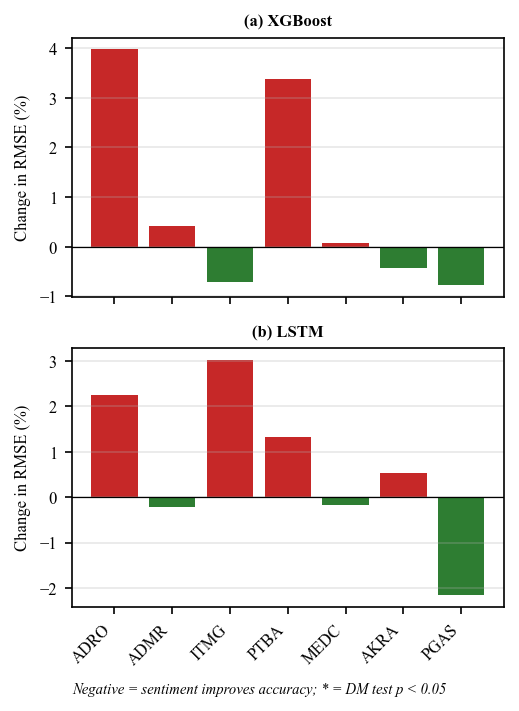

💾 gambar_ablation_sentimen.png tersimpan.


In [8]:
plt.rcParams.update({'font.size': 8, 'axes.titlesize': 8, 'legend.fontsize': 7})
fig, axes = plt.subplots(2, 1, figsize=(3.5, 4.6), sharex=True)
x = np.arange(len(URUTAN_EMITEN))
for ax, mdl, huruf in zip(axes, ['XGBoost', 'LSTM'], 'ab'):
    d = df_abl[df_abl.Model == mdl].set_index('Emiten').loc[URUTAN_EMITEN]
    warna = ['#2E7D32' if v < 0 else '#C62828' for v in d['Perubahan_RMSE_%']]
    bars = ax.bar(x, d['Perubahan_RMSE_%'], color=warna)
    for b_, p in zip(bars, d['p_value']):
        if p < 0.05:
            ax.annotate('*', (b_.get_x() + b_.get_width() / 2, b_.get_height()),
                        ha='center', va='bottom' if b_.get_height() >= 0 else 'top', fontsize=10)
    ax.axhline(0, color='black', lw=0.6)
    ax.set_title(f'({huruf}) {mdl}', fontweight='bold'); ax.set_ylabel('Change in RMSE (%)')
    ax.grid(axis='y', alpha=0.3)
axes[-1].set_xticks(x); axes[-1].set_xticklabels(URUTAN_EMITEN, rotation=45, ha='right')
fig.text(0.5, -0.01, 'Negative = sentiment improves accuracy; * = DM test p < 0.05', ha='center', fontsize=7, style='italic')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_ablation_sentimen.png', dpi=600, bbox_inches='tight')
plt.show()
print('💾 gambar_ablation_sentimen.png tersimpan.')